# Latency and SHAP Feature Importance

GEOG761 Group 05. A trimmed copy of `flood_event_pipeline.ipynb` with only what is needed to (1) time inference and (2) rank the input bands with SHAP. Tuning, baselines, depth and exposure are left out; the final model settings are fixed (200 trees, minimum leaf 5, all 11 bands, threshold 0.425).

**Before running:** the reference polygons must be at `TEST_DIR`. Run top to bottom in Colab. Outputs in `OUT_DIR`: `latency.csv`, `shap_importance.csv`, `shap_summary.png`.

In [ ]:
!pip install -q geemap geedim rasterio shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 62.9 MB/s eta 0:00:00


In [ ]:
import ee

ee.Authenticate()
EE_PROJECT = "basic-thinker-504003-q7"   # replace with your own GEE Cloud project if you get a permission error
ee.Initialize(project=EE_PROJECT)
print("Earth Engine ready, project:", EE_PROJECT)

Earth Engine ready, project: basic-thinker-504003-q7


In [ ]:
from google.colab import drive

drive.mount("/content/drive")   # layers from flood_data_pipeline.ipynb live on Drive

Mounted at /content/drive


In [ ]:
from pathlib import Path
import itertools
import logging
import time
import numpy as np
import pandas as pd
import geopandas as gpd
import geemap
from shapely.geometry import box

logging.getLogger("urllib3.connectionpool").setLevel(logging.ERROR)   # harmless "connection pool is full" spam during the GeoTIFF download

# --- Reference flood polygons (Cyclone Gabrielle) -----------------------------
TEST_DIR = Path("/content/drive/MyDrive/GEOG 761 Group Project/Project Data/test")
AOIS = ["01", "02", "03", "04", "05", "06"]   # Northland AOIs used for training and testing (07 = validation, not needed here)
SPLIT = {
    "train": ["01", "02", "05", "06"],
    "test":  ["03", "04"],
}

# --- Processing / sampling ------------------------------------------------------
SCALE_M = 20             # reference polygons are on a 20 m grid
SPECKLE_RADIUS_M = 50    # boxcar filter, as in Lecture 6
TRAIN_PER_CLASS = 500    # per training AOI, flood and dry each (balanced)
EVAL_PIXELS = 20000      # per validation/test AOI, random pixels = real flood share (masked pixels are dropped after sampling, so fewer come back)
SEED = 42
JRC_PERMANENT_PCT = 10   # JRC occurrence above this = permanent water
EDGE_BUFFER_M = 20       # training only: pixels this close to a polygon edge are dropped from both classes (boundary is uncertain)
HAND_MAX_M = 10          # study area = ground at most this high above the nearest drainage (floodable land)

# --- Final model (settings the full pipeline selected; see README) -----------------
BEST_TREES, BEST_LEAF = 200, 5
THRESHOLD = 0.425

# --- Northland flood map -----------------------------------
MAP_SCALE_M = 30         # Northland at 30 m is ~55 M pixels; 20 m would more than double memory
MIN_PATCH_PIXELS = 8     # drop flood clusters smaller than this (noise)

OUT_DIR = Path("/content/drive/MyDrive/GEOG 761 Group Project/Project Data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
ref = pd.concat([gpd.read_file(p) for p in sorted(TEST_DIR.glob("*.geojson"))], ignore_index=True)
ref["aoi_id"] = ref["aoi_id"].astype(str).str.zfill(2)
ref = ref[ref["aoi_id"].isin(AOIS)].reset_index(drop=True)

aois = ref.groupby("aoi_id").agg(
    polygons=("flood_id", "size"),
    flood_ha=("area_ha", "sum"),
    event_date_utc=("event_date_utc", "first"),
    before_start=("before_start", "first"),
    before_end=("before_end", "first"),
    relative_orbit=("relative_orbit", "first"),
).join(ref.dissolve("aoi_id").bounds)

split_of = {a: s for s, ids in SPLIT.items() for a in ids}
assert set(split_of) == set(aois.index), f"SPLIT and AOIs differ: {set(split_of) ^ set(aois.index)}"
aois["split"] = aois.index.map(split_of)

boxes = gpd.GeoSeries([box(*b) for b in aois[["minx", "miny", "maxx", "maxy"]].values], index=aois.index, crs=4326).to_crs(2193)
aois["flood_pct"] = (100 * aois["flood_ha"] / (boxes.area / 1e4)).round(1)

# Overlapping AOIs in different splits would leak the same pixels into training and test.
for a, b in itertools.combinations(aois.index, 2):
    if boxes[a].intersects(boxes[b]) and not boxes[a].touches(boxes[b]):
        assert split_of[a] == split_of[b], f"AOIs {a} and {b} overlap but are in different splits"

aois[["split", "polygons", "flood_ha", "flood_pct", "relative_orbit", "event_date_utc", "before_start", "before_end"]]

,split,polygons,flood_ha,flood_pct,relative_orbit,event_date_utc,before_start,before_end
aoi_id,,,,,,,,
01,train,198,2680.744257,6.8,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
02,train,377,3684.501480,9.3,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
03,test,377,1960.711827,6.1,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
04,test,203,1212.048515,3.1,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
05,train,71,564.698672,2.5,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
06,train,127,3131.543900,14.2,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12


In [ ]:
def s1_collection(region, start, end, rel_orbit=None):
    col = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(region)
        .filterDate(start, end)
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
    )
    if rel_orbit is not None:
        col = col.filter(ee.Filter.eq("relativeOrbitNumber_start", int(rel_orbit)))
    return col.select(["VV", "VH"])


def around(t, hours=1):
    """[start, end] in epoch ms, `hours` either side of timestamp t."""
    return [int((t + pd.Timedelta(hours=h)).timestamp() * 1000) for h in (-hours, hours)]


def sar_features(img, prefix):
    img = img.focal_mean(radius=SPECKLE_RADIUS_M, units="meters")
    img = img.addBands(img.select("VV").subtract(img.select("VH")).rename("VV_VH"))
    return img.rename([f"{prefix}_VV", f"{prefix}_VH", f"{prefix}_VV_VH"])


dem_ic = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1").select("DEM")
elevation = dem_ic.mosaic().setDefaultProjection(
    dem_ic.filterBounds(ee.Geometry.Point(173.9, -35.6)).first().projection()).rename("elev")   # tiles vary in resolution; use a Northland one
slope = ee.Terrain.slope(elevation).rename("slope")
hand = ee.Image("MERIT/Hydro/v1_0_1").select("hnd").rename("hand")
worldcover = ee.Image("ESA/WorldCover/v200/2021").select("Map")
jrc = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").unmask(0)
permanent_water = worldcover.eq(80).Or(jrc.gt(JRC_PERMANENT_PCT)).rename("perm")


def feature_stack(pre_col, post_col):
    pre = sar_features(pre_col.median(), "pre")
    post = sar_features(post_col.mosaic(), "post")
    change = (
        post.select(["post_VV", "post_VH"]).subtract(pre.select(["pre_VV", "pre_VH"]))
        .rename(["d_VV", "d_VH"])
    )
    return ee.Image.cat([pre, post, change, elevation, slope, hand, permanent_water])


FEATURES = ["pre_VV", "pre_VH", "pre_VV_VH", "post_VV", "post_VH", "post_VV_VH", "d_VV", "d_VH", "elev", "slope", "hand"]


def aoi_region(a):
    r = aois.loc[a]
    return ee.Geometry.Rectangle([r.minx, r.miny, r.maxx, r.maxy])


def aoi_cols(a):
    r = aois.loc[a]
    region = aoi_region(a)
    pre = s1_collection(region, r.before_start, r.before_end, r.relative_orbit)
    post = s1_collection(region, *around(pd.Timestamp(r.event_date_utc, tz="UTC")), r.relative_orbit)
    return pre, post


def aoi_label(a):
    near = ref[ref.intersects(box(*aois.loc[a, ["minx", "miny", "maxx", "maxy"]]))]
    return ee.Image(0).byte().paint(geemap.gdf_to_ee(near[["geometry"]]), 1).rename("label")


def aoi_stack(a):
    return feature_stack(*aoi_cols(a)).addBands(aoi_label(a)).clip(aoi_region(a))


counts = ee.Dictionary({a: [c.size() for c in aoi_cols(a)] for a in aois.index}).getInfo()
aois["pre_scenes"] = [counts[a][0] for a in aois.index]
aois["event_scenes"] = [counts[a][1] for a in aois.index]
display(aois[["split", "relative_orbit", "pre_scenes", "event_scenes"]])
missing = aois.index[(aois["pre_scenes"] == 0) | (aois["event_scenes"] == 0)].tolist()
assert not missing, f"No Sentinel-1 scene for AOIs {missing}: check their dates / orbit."

,split,relative_orbit,pre_scenes,event_scenes
aoi_id,,,,
01,train,81.0,2,1
02,train,81.0,2,1
03,test,81.0,2,1
04,test,81.0,2,1
05,train,81.0,2,1
06,train,81.0,2,1


In [ ]:
def study_area(label, edge_m=EDGE_BUFFER_M):
    area = permanent_water.Not().And(hand.lt(HAND_MAX_M))
    if not edge_m:
        return area
    r = dict(radius=edge_m, kernelType="circle", units="meters")
    edge = label.focal_max(**r).neq(label.focal_min(**r))
    return area.And(edge.Not())


def sample_aoi(a, edge_m=None):
    if edge_m is None:   # edge band for training only; valid/test are scored on every pixel
        edge_m = EDGE_BUFFER_M if split_of[a] == "train" else 0
    stack = aoi_stack(a)
    stack = stack.updateMask(study_area(stack.select("label"), edge_m))
    region, split = aoi_region(a), split_of[a]
    if split == "train":
        fc = stack.stratifiedSample(
            numPoints=TRAIN_PER_CLASS, classBand="label", region=region, scale=SCALE_M,
            projection="EPSG:2193", seed=SEED, classValues=[0, 1],
            classPoints=[TRAIN_PER_CLASS, TRAIN_PER_CLASS], geometries=False,
        )
    else:   # test
        fc = stack.sample(region=region, scale=SCALE_M, projection="EPSG:2193",
                          numPixels=EVAL_PIXELS, seed=SEED, geometries=False)
    return fc.map(lambda f: f.set({"aoi_id": a, "split": split}))


def to_df(fc):
    df = ee.data.computeFeatures({"expression": fc, "fileFormat": "PANDAS_DATAFRAME"})
    return df.drop(columns="geo", errors="ignore")


samples_fc = {a: sample_aoi(a) for a in aois.index}
df = pd.concat([to_df(samples_fc[a]) for a in aois.index], ignore_index=True)
train_df, test_df = (df[df["split"] == s].reset_index(drop=True) for s in ("train", "test"))
print(f"Train pixels: {len(train_df)} | test pixels: {len(test_df)}")


Train pixels: 4000 | test pixels: 12085


## Latency

scikit-learn timings are local CPU. Earth Engine runs server-side and is lazy, so its timings include the network round trip and, for the Northland one, the GeoTIFF download.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

BEST_BANDS = FEATURES
timings = {}

t0 = time.perf_counter()
rf = RandomForestClassifier(n_estimators=BEST_TREES, min_samples_leaf=BEST_LEAF, random_state=SEED, n_jobs=-1).fit(
    train_df[BEST_BANDS], train_df["label"])
timings["sklearn train (s)"] = time.perf_counter() - t0

rf.predict_proba(test_df[BEST_BANDS])   # warm-up (thread pool start)
runs = []
for _ in range(5):
    t0 = time.perf_counter()
    rf.predict_proba(test_df[BEST_BANDS])
    runs.append(time.perf_counter() - t0)
timings["sklearn inference, all test pixels, median of 5 (s)"] = float(np.median(runs))
timings["sklearn inference per 1000 pixels (ms)"] = 1000 * float(np.median(runs)) * 1000 / len(test_df)
print(f"{len(test_df)} test pixels: {np.median(runs):.3f} s")


12085 test pixels: 0.102 s


In [ ]:
train_fc = ee.FeatureCollection([ee.Feature(None, r) for r in train_df[BEST_BANDS + ["label"]].round(3).to_dict("records")])
gee_rf = (
    ee.Classifier.smileRandomForest(numberOfTrees=BEST_TREES, minLeafPopulation=BEST_LEAF, seed=SEED)
    .setOutputMode("PROBABILITY")
    .train(features=train_fc, classProperty="label", inputProperties=BEST_BANDS)
)

# Earth Engine is lazy: training and classify run server-side when the result is fetched.
test_fc = ee.FeatureCollection([samples_fc[a] for a in SPLIT["test"]]).flatten()
t0 = time.perf_counter()
to_df(test_fc.classify(gee_rf, "p"))
timings["Earth Engine train + classify test pixels + fetch (s)"] = time.perf_counter() - t0
print(f"{timings['Earth Engine train + classify test pixels + fetch (s)']:.1f} s")


78.9 s


In [ ]:
NORTHLAND = (
    ee.FeatureCollection("FAO/GAUL/2015/level1")
    .filter(ee.Filter.eq("ADM0_NAME", "New Zealand"))
    .filter(ee.Filter.eq("ADM1_NAME", "Northland"))
    .geometry()
)
event_cols = ["event_date_utc", "before_start", "before_end", "relative_orbit"]
assert (aois[event_cols].nunique() == 1).all(), "Northland AOIs disagree on the event pass / pre-event window"
ev = aois.iloc[0]

stack_nl = feature_stack(
    s1_collection(NORTHLAND, ev.before_start, ev.before_end, ev.relative_orbit),
    s1_collection(NORTHLAND, *around(pd.Timestamp(ev.event_date_utc, tz="UTC")), ev.relative_orbit),
).clip(NORTHLAND)
flood_prob = stack_nl.select(BEST_BANDS).classify(gee_rf).rename("flood_prob")
flood = flood_prob.gte(THRESHOLD).And(permanent_water.Not()).And(hand.lt(HAND_MAX_M))   # same study area as training
flood = flood.And(flood.selfMask().connectedPixelCount(100, True).gte(MIN_PATCH_PIXELS).unmask(0)).rename("flood").toByte()

flood_path = OUT_DIR / "latency_northland_flood.tif"
t0 = time.perf_counter()   # Earth Engine is lazy: classify runs server-side here, so this times classify + download
geemap.download_ee_image(flood, filename=str(flood_path), region=NORTHLAND, scale=MAP_SCALE_M, crs="EPSG:2193")
print("Saved:", flood_path)
timings["Earth Engine classify + download, Northland, one pass (s)"] = time.perf_counter() - t0
print(f"Classify + download (Northland, one pass): {timings['Earth Engine classify + download, Northland, one pass (s)']:.1f} s")

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)
/usr/local/lib/python3.13/dist-packages/geemap/common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)


  0%|          |0/34 tiles [00:00<?]

Saved: /content/drive/MyDrive/GEOG 761 Group Project/Project Data/processed/latency_northland_flood.tif
Classify + download (Northland, one pass): 331.8 s


/usr/local/lib/python3.13/dist-packages/geedim/image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


In [ ]:
lat = pd.Series(timings, name="value").round(3)
lat.to_csv(OUT_DIR / "latency.csv")
lat

,value
sklearn train (s),1.219
"sklearn inference, all test pixels, median of 5 (s)",0.102
sklearn inference per 1000 pixels (ms),8.451
Earth Engine train + classify test pixels + fetch (s),78.896
"Earth Engine classify + download, Northland, one pass (s)",331.790


## SHAP feature importance

d_VH          0.2648
post_VH       0.1270
post_VV_VH    0.0502
d_VV          0.0289
slope         0.0232
post_VV       0.0164
hand          0.0066
elev          0.0042
pre_VV        0.0019
pre_VH        0.0018
pre_VV_VH     0.0004


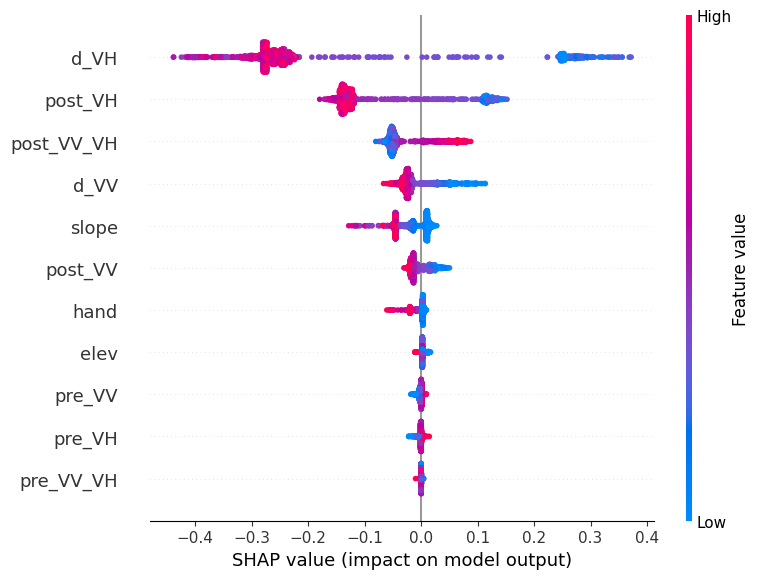

In [ ]:
import matplotlib.pyplot as plt
import shap

# Mean |SHAP| of the flood probability, on a test sample (TreeExplainer is exact for the scikit-learn RF).
X_shap = test_df[BEST_BANDS].sample(min(2000, len(test_df)), random_state=SEED)
sv = shap.TreeExplainer(rf).shap_values(X_shap)
sv = sv[1] if isinstance(sv, list) else sv[..., 1]   # flood class; older shap returns a list, newer a 3-D array
shap_importance = pd.Series(np.abs(sv).mean(axis=0), BEST_BANDS).sort_values(ascending=False)
shap_importance.rename("mean_abs_shap").to_csv(OUT_DIR / "shap_importance.csv")
print(shap_importance.round(4).to_string())

shap.summary_plot(sv, X_shap, show=False)
plt.gcf().savefig(OUT_DIR / "shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()